# Exam 3: Part 2 Solution

Complete the notebook using the instructions that follow.

Reminder: You are permitted to use the following resources:

* https://numpy.org/doc/stable/reference/
* https://pandas.pydata.org/docs/reference/index.html
* https://matplotlib.org/stable/api/index.html
* https://scikit-learn.org/stable/api/index.html
* https://scipy.org/

No AI use is permitted. No Googling or searching sites beyond the permitted sites listed above. No looking at notes or talking with others.

To turn off AI in colab:
1. Go to Tools > Settings
2. Select AI Assistance menu
3. Uncheck "Show AI-powered inline completions"
4. Check "Hide generative AI features"

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn import metrics # for confusion matrix
from sklearn.metrics import accuracy_score # for evaluating our classification model
from sklearn.model_selection import train_test_split

The Breast Cancer Dataset contains 569 observations with 30 features. We can use this labeled data to develop a model that predicts whether a tumor is **malignant** (cancerous) or **benign** (non-cancerous) based on features extracted from a digitized image of a fine needle aspirate (FNA) of a mass.

In [6]:
df = load_breast_cancer(as_frame=True)
df.data

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


To simplify this for the purpose of the exam, we'll only be using the first 10 features of the dataset:

In [8]:
X = df.data.iloc[:,:-20] #removes last 20 columns
y = df.target
print("X values")
print(X.head())
print("y values")
print(y.head())

X values
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  
0                 0.07871  
1                 0.05667  

Complete the steps that follow. Each step is worth 2 points.

1. Write the line of code needed below to split the data into training and testing data using a 75/25 split. Don't forget to add any imports needed.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=5, test_size=0.25)

2. Now create AND train the appropriate model here. Choose from either linear or logistic regression. Don't forget any imports needed.

In [20]:
model = LogisticRegression(random_state=0, max_iter = 500).fit(X_train, y_train)

3. Predict the labels for the test class data. Store these values as y_pred.

In [25]:
y_pred=model.predict(X_test)

4. Write the code needed to evaluate the model. Consider the appropriate metric to use here. Don't forget to include any imports needed.

In [30]:
accuracy_score(y_true=y_test, y_pred=model.predict(X_test))

0.9440559440559441

5.  How did the model do? What is your interpretation?

Accuracy is about 94%. This is not too bad... but there is still about 5% error.  Would use with caution given the application area (healthcare). 

6.  Consider the assumptions of the model you used.  Are at least 2 assumptions for this model met?  Explain why or why not.



Assumptions
1. predicted value is dichotomous (yes, our label is either yes/1 or no/0)
2. observations are independent (yes, each row is an independent observation) 
3. Linear relationship between continuous independent variables and the logit transformation of the dependent variable (inspect with scatter plots) (did not include here)
4. Requires little to no multicollinearity among independent variable (see below)

<Axes: >

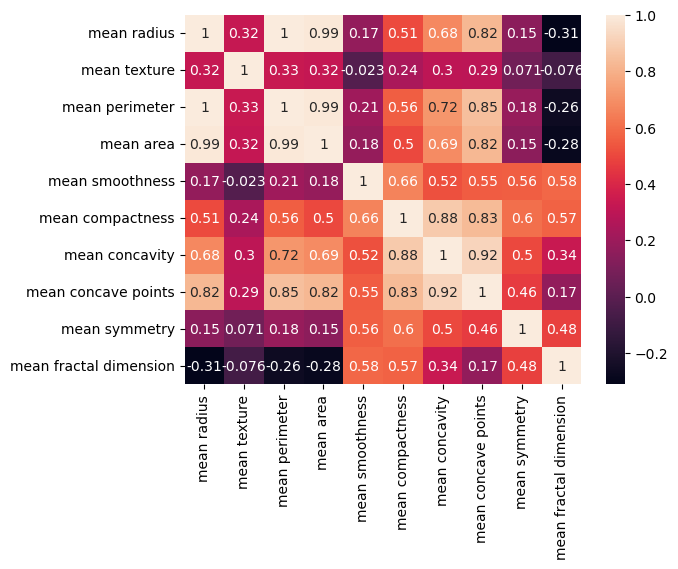

In [37]:
# There are some strong correlations unfortunately 
sns.heatmap(X.corr(), annot=True)

7. Consider imbalance.

(1) Is class imbalance present in this dataset?

(2) Why or why not? Be sure to include any code you used to justify your answer.

(3) What could be the impact of severe class imbalance?

In [33]:
y.value_counts()

target
1    357
0    212
Name: count, dtype: int64

(1) Yes, there is a slight class imbalance. Probably is not significant here because the imbalance is not severe. <br />
(2) 357 observations have a positive (1) y value while only 212 have a negative (0) y value. There number of classes is not equal. <br />
(3) The model might not train properly if it does not have enough negative values to learn from. Might have bias towards majority (positive). 

That's it! To submit your work, go to **File** > **Download the .ipynb** and upload it to the PLATO dropbox. Please double-check your submission.